full I (kg m^2):
 [[ 2.  0. -2.]
 [ 0.  4.  0.]
 [-2.  0.  2.]]
row z from STEP 2: [-2.  0.  2.]  matches full I: True
contributions (x, y, z parts): [-2.  0.  4.]  L_z = 2.0  full L = I w = [-2.  0.  2.]
saved the figure


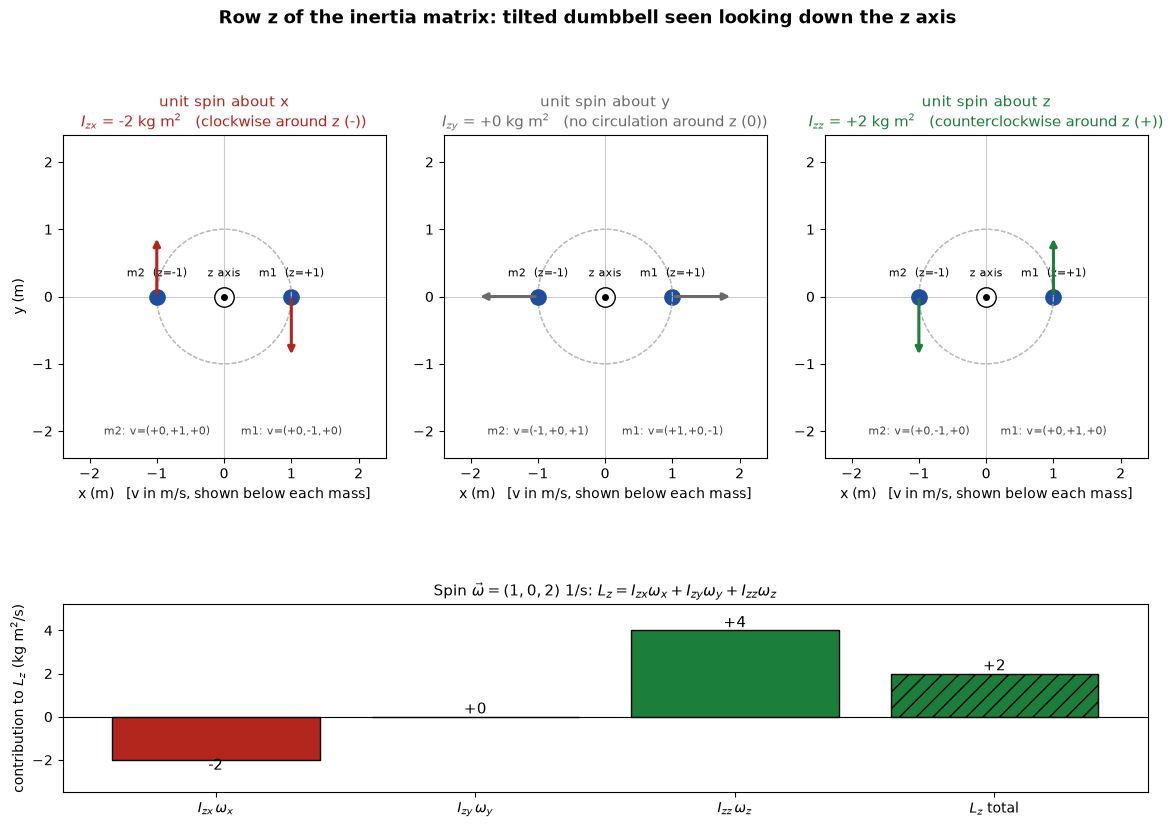

In [1]:
import os
from datetime import datetime

import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore
from matplotlib.gridspec import GridSpec  # type: ignore

RESULT_DIR = os.path.join(os.getcwd(), "result")
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

# ---------------------------------------------------------------
# STEP 1: the body (tilted dumbbell)
# What we have: two masses (kg) at positions r_i (m).
# What we want: the row z of the inertia matrix, (I_zx, I_zy, I_zz).
# Why: row z builds L_z = I_zx w_x + I_zy w_y + I_zz w_z.
# ---------------------------------------------------------------
M = np.array([1.0, 1.0])
R = np.array([[1.0, 0.0, 1.0], [-1.0, 0.0, -1.0]])
UNIT = {"x": np.array([1.0, 0.0, 0.0]),
        "y": np.array([0.0, 1.0, 0.0]),
        "z": np.array([0.0, 0.0, 1.0])}

# ---------------------------------------------------------------
# STEP 2: unit spin about each axis b, velocity and L_z per mass
# What we have: w = e_b (1 1/s), v_i = e_b x r_i
# What we want: L_z,i = m_i (x_i v_y,i - y_i v_x,i)
# Why: L_z is the circulation around the z axis, so it only needs
#      the x,y parts of position and velocity (the view down z).
#      I_zb = sum_i L_z,i
# ---------------------------------------------------------------
V = {}
LZ = {}
IZ = {}
for b, e in UNIT.items():
    V[b] = np.cross(e, R)
    LZ[b] = M * (R[:, 0] * V[b][:, 1] - R[:, 1] * V[b][:, 0])
    IZ[b] = LZ[b].sum()

# ---------------------------------------------------------------
# STEP 3: check against the full inertia matrix
# What we have: per-mass formula
#   I = m [[y2+z2, -xy, -xz], [-xy, x2+z2, -yz], [-xz, -yz, x2+y2]]
# What we want: confirm row z equals (I_zx, I_zy, I_zz) from STEP 2
# ---------------------------------------------------------------
I_FULL = np.zeros((3, 3))
for m, (x, y, z) in zip(M, R):
    I_FULL += m * np.array([[y * y + z * z, -x * y, -x * z],
                            [-x * y, x * x + z * z, -y * z],
                            [-x * z, -y * z, x * x + y * y]])
row_z = np.array([IZ["x"], IZ["y"], IZ["z"]])
print("full I (kg m^2):\n", I_FULL)
print("row z from STEP 2:", row_z, " matches full I:", np.allclose(I_FULL[2], row_z))

# ---------------------------------------------------------------
# STEP 4: a mixed spin, w = (1, 0, 2) 1/s
# What we have: row z and w
# What we want: the three contributions to L_z and their sum
# Why: L_z = I_zx w_x + I_zy w_y + I_zz w_z
# ---------------------------------------------------------------
W = np.array([1.0, 0.0, 2.0])
contrib = row_z * W
LZ_TOTAL = contrib.sum()
print("contributions (x, y, z parts):", contrib, " L_z =", LZ_TOTAL,
      " full L = I w =", I_FULL @ W)

# ---------------------------------------------------------------
# STEP 5: figure
# Top row: view looking down the z axis (x right, y up, z toward you).
#   One panel per unit spin. Dots are the masses, arrows are the x,y
#   parts of the velocity, dashed circle is the path around z.
# Bottom: contributions to L_z for w = (1, 0, 2).
# ---------------------------------------------------------------
POS, NEG, ZERO = "#1b7f3b", "#b3261e", "#6b6b6b"

fig = plt.figure(figsize=(14, 9))
gs = GridSpec(2, 3, height_ratios=[2.1, 1.0], hspace=0.38, wspace=0.18)

for col, b in enumerate(["x", "y", "z"]):
    ax = fig.add_subplot(gs[0, col])
    ax.set_aspect("equal")
    ax.set_xlim(-2.4, 2.4)
    ax.set_ylim(-2.4, 2.4)
    ax.axhline(0, color="#cccccc", lw=0.8)
    ax.axvline(0, color="#cccccc", lw=0.8)
    ax.set_xlabel("x (m)   [v in m/s, shown below each mass]")
    if col == 0:
        ax.set_ylabel("y (m)")

    # the z axis points at the viewer: draw as a circle with a dot
    ax.plot(0, 0, "o", ms=14, mfc="white", mec="black")
    ax.plot(0, 0, "o", ms=4, color="black")
    ax.text(0.0, 0.3, "z axis", fontsize=8, ha="center")

    for i in range(len(M)):
        x, y, z = R[i]
        vx, vy, vz = V[b][i]
        radius = np.hypot(x, y)
        if radius > 0:
            th = np.linspace(0, 2 * np.pi, 200)
            ax.plot(radius * np.cos(th), radius * np.sin(th), ls="--",
                    color="#bbbbbb", lw=0.9)
        ax.plot(x, y, "o", ms=11, color="#1f4e9c")
        ax.text(x, y + 0.3, f"m{i + 1}  (z={z:+.0f})", fontsize=8, ha="center")
        if abs(vx) + abs(vy) > 0:
            lzi = LZ[b][i]
            colr = POS if lzi > 0 else (NEG if lzi < 0 else ZERO)
            ax.annotate("", xy=(x + 0.9 * vx, y + 0.9 * vy), xytext=(x, y),
                        arrowprops=dict(arrowstyle="-|>", color=colr, lw=2.2))
        ax.text(x, -2.05, f"m{i + 1}: v=({vx + 0.0:+.0f},{vy + 0.0:+.0f},{vz + 0.0:+.0f})",
                fontsize=8, color="#444444", ha="center")

    iz = IZ[b]
    if iz > 0:
        sense, colr = "counterclockwise around z (+)", POS
    elif iz < 0:
        sense, colr = "clockwise around z (-)", NEG
    else:
        sense, colr = "no circulation around z (0)", ZERO
    ax.set_title(f"unit spin about {b}\n"
                 + rf"$I_{{z{b}}}$ = {iz:+.0f} kg m$^2$   ({sense})",
                 fontsize=10.5, color=colr)

axb = fig.add_subplot(gs[1, :])
labels = [r"$I_{zx}\,\omega_x$", r"$I_{zy}\,\omega_y$", r"$I_{zz}\,\omega_z$",
          r"$L_z$ total"]
vals = list(contrib) + [LZ_TOTAL]
cols = [POS if v > 0 else (NEG if v < 0 else ZERO) for v in vals]
bars = axb.bar(labels, vals, color=cols, edgecolor="black")
bars[-1].set_hatch("//")
axb.axhline(0, color="black", lw=0.8)
for bar, v in zip(bars, vals):
    axb.text(bar.get_x() + bar.get_width() / 2, v + (0.15 if v >= 0 else -0.45),
             f"{v:+.0f}", ha="center", fontsize=11)
axb.set_ylim(-3.5, 5.2)
axb.set_ylabel(r"contribution to $L_z$ (kg m$^2$/s)")
axb.set_title(r"Spin $\vec\omega=(1,0,2)$ 1/s: "
              r"$L_z=I_{zx}\omega_x+I_{zy}\omega_y+I_{zz}\omega_z$", fontsize=11)

fig.suptitle("Row z of the inertia matrix: tilted dumbbell seen looking down the z axis",
             fontsize=13, fontweight="bold")

out_path = os.path.join(RESULT_DIR, f"row_z_visual_{TIMESTAMP}.png")
fig.savefig(out_path, dpi=140, bbox_inches="tight")
print("saved the figure")
plt.show()

I_zx, I_zy, I_zz = -2.0 0.0 2.0
saved the figure


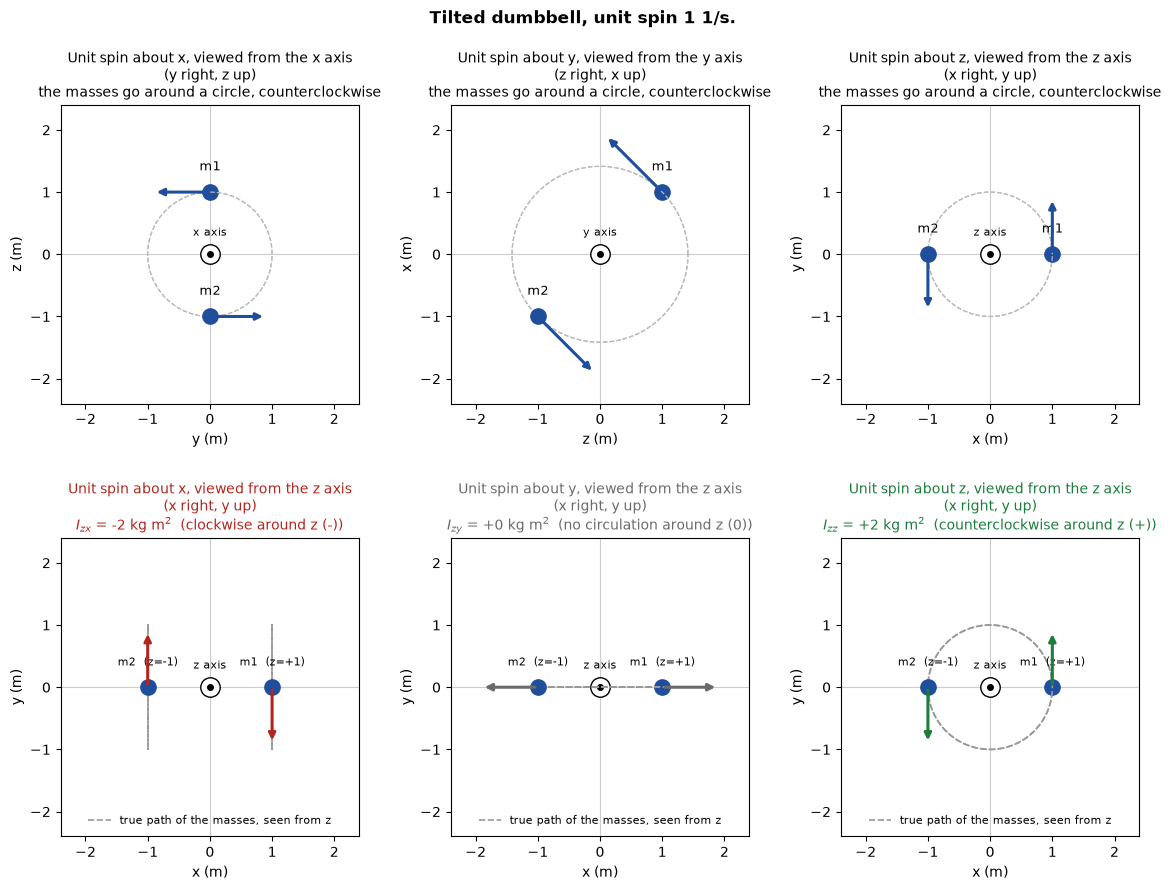

In [4]:
import os
from datetime import datetime

import numpy as np  # type: ignore
import matplotlib.pyplot as plt  # type: ignore
from matplotlib.gridspec import GridSpec  # type: ignore

RESULT_DIR = os.path.join(os.getcwd(), "result")
os.makedirs(RESULT_DIR, exist_ok=True)
TIMESTAMP = datetime.now().strftime("%Y%m%d_%H%M%S")

# ---------------------------------------------------------------
# STEP 1: the body (tilted dumbbell) and the three unit spins
# What we have: two masses (kg) at r_i (m), unit spin 1 1/s about x, y, z
# What we want: velocities v_i = e_b x r_i for each spin
# Why: the same motion is looked at in two different views
# ---------------------------------------------------------------
M = np.array([1.0, 1.0])
R = np.array([[1.0, 0.0, 1.0], [-1.0, 0.0, -1.0]])
UNIT = {"x": np.array([1.0, 0.0, 0.0]),
        "y": np.array([0.0, 1.0, 0.0]),
        "z": np.array([0.0, 0.0, 1.0])}
V = {b: np.cross(e, R) for b, e in UNIT.items()}

# ---------------------------------------------------------------
# STEP 2: the readout, L_z per mass and I_zb
# What we have: v_i
# What we want: L_z,i = m_i (x_i v_y,i - y_i v_x,i), I_zb = sum_i L_z,i
# Why: L_z only looks at the x,y parts (view down the z axis)
# ---------------------------------------------------------------
LZ = {b: M * (R[:, 0] * V[b][:, 1] - R[:, 1] * V[b][:, 0]) for b in UNIT}
IZ = {b: LZ[b].sum() for b in UNIT}
print("I_zx, I_zy, I_zz =", IZ["x"], IZ["y"], IZ["z"])

# ---------------------------------------------------------------
# STEP 3: pick the two views
# View A (spin view): look DOWN THE SPIN AXIS. The motion is a pure
#   circle there. Right-handed screen coordinates (horizontal, vertical):
#   down x: (y, z)    down y: (z, x)    down z: (x, y)
# View B (readout view): always look DOWN z, screen (x, y).
# ---------------------------------------------------------------
SCREEN = {"x": (1, 2), "y": (2, 0), "z": (0, 1)}
NAMES = ["x", "y", "z"]
POS, NEG, ZERO = "#1b7f3b", "#b3261e", "#6b6b6b"
SPIN_COL = "#1f4e9c"


def draw_frame(ax, hlabel, vlabel):
    ax.set_aspect("equal")
    ax.set_xlim(-2.4, 2.4)
    ax.set_ylim(-2.4, 2.4)
    ax.axhline(0, color="#cccccc", lw=0.8)
    ax.axvline(0, color="#cccccc", lw=0.8)
    ax.set_xlabel(hlabel)
    ax.set_ylabel(vlabel)
    ax.plot(0, 0, "o", ms=14, mfc="white", mec="black")
    ax.plot(0, 0, "o", ms=4, color="black")


def path_xy(e, r, n=240):
    """x,y of the mass as it turns once about axis e (Rodrigues rotation)."""
    t = np.linspace(0, 2 * np.pi, n)
    pts = (np.outer(np.cos(t), r) + np.outer(np.sin(t), np.cross(e, r))
           + np.outer(1 - np.cos(t), e * np.dot(e, r)))
    return pts[:, 0], pts[:, 1]


fig = plt.figure(figsize=(14, 9.5))
gs = GridSpec(2, 3, hspace=0.45, wspace=0.28)

for col, b in enumerate(["x", "y", "z"]):
    hi, vi = SCREEN[b]
    # ---------------- row 1: spin view (look down the spin axis) -------------
    ax = fig.add_subplot(gs[0, col])
    draw_frame(ax, f"{NAMES[hi]} (m)", f"{NAMES[vi]} (m)")
    ax.text(0.0, 0.3, f"{b} axis", fontsize=8, ha="center")
    for i in range(len(M)):
        h, v = R[i, hi], R[i, vi]
        vh, vv = V[b][i, hi], V[b][i, vi]
        rad = np.hypot(h, v)
        th = np.linspace(0, 2 * np.pi, 200)
        ax.plot(rad * np.cos(th), rad * np.sin(th), ls="--", color="#bbbbbb", lw=0.9)
        ax.plot(h, v, "o", ms=11, color="#1f4e9c")
        ax.text(h, v + 0.35, f"m{i + 1}", fontsize=9, ha="center")
        ax.annotate("", xy=(h + 0.9 * vh, v + 0.9 * vv), xytext=(h, v),
                    arrowprops=dict(arrowstyle="-|>", color=SPIN_COL, lw=2.2))
    ax.set_title(f"Unit spin about {b}, viewed from the {b} axis\n"
                 f"({NAMES[hi]} right, {NAMES[vi]} up)\n"
                 "the masses go around a circle, counterclockwise", fontsize=10)

    # ---------------- row 2: readout view (always look down z) ---------------
    ax2 = fig.add_subplot(gs[1, col])
    draw_frame(ax2, "x (m)", "y (m)")
    ax2.text(0.0, 0.3, "z axis", fontsize=8, ha="center")
    for i in range(len(M)):
        x, y, z = R[i]
        vx, vy, vz = V[b][i]
        px, py = path_xy(UNIT[b], R[i])
        ax2.plot(px, py, ls="--", color="#999999", lw=1.2,
                 label="true path of the masses, seen from z" if i == 0 else None)
        ax2.plot(x, y, "o", ms=11, color="#1f4e9c")
        ax2.text(x, y + 0.35, f"m{i + 1}  (z={z:+.0f})", fontsize=8, ha="center")
        lzi = LZ[b][i]
        colr = POS if lzi > 0 else (NEG if lzi < 0 else ZERO)
        if abs(vx) + abs(vy) > 0:
            ax2.annotate("", xy=(x + 0.9 * vx, y + 0.9 * vy), xytext=(x, y),
                         arrowprops=dict(arrowstyle="-|>", color=colr, lw=2.2))
    ax2.legend(loc="lower center", fontsize=8, frameon=False)
    iz = IZ[b]
    if iz > 0:
        sense, colr = "counterclockwise around z (+)", POS
    elif iz < 0:
        sense, colr = "clockwise around z (-)", NEG
    else:
        sense, colr = "no circulation around z (0)", ZERO
    ax2.set_title(f"Unit spin about {b}, viewed from the z axis\n"
                  "(x right, y up)\n"
                  + rf"$I_{{z{b}}}$ = {iz:+.0f} kg m$^2$  ({sense})",
                  fontsize=10, color=colr)

fig.suptitle("Tilted dumbbell, unit spin 1 1/s.",
             fontsize=12.5, fontweight="bold")

out_path = os.path.join(RESULT_DIR, f"row_z_two_views_{TIMESTAMP}.png")
fig.savefig(out_path, dpi=140, bbox_inches="tight")
print("saved the figure")
plt.show()